<a href="https://colab.research.google.com/github/Lasan-Perera/EN3160-assignment-3/blob/main/CV_assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from google.colab import drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/10, Loss: 2.2081
Epoch 2/10, Loss: 2.0136
Epoch 3/10, Loss: 1.9298
Epoch 4/10, Loss: 1.8822
Epoch 5/10, Loss: 1.8459
Epoch 6/10, Loss: 1.8165
Epoch 7/10, Loss: 1.7923
Epoch 8/10, Loss: 1.7720
Epoch 9/10, Loss: 1.7541
Epoch 10/10, Loss: 1.7382

Training accuracy: 39.49%
Test accuracy: 39.43%


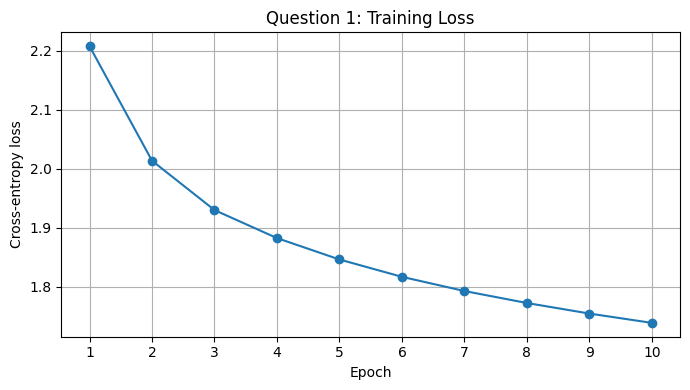

In [8]:
drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/CIFAR10"
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,)*3, (0.5,)*3)])
trainset = torchvision.datasets.CIFAR10(root=data_path, train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root=data_path, train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=50, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=50, shuffle=False)

Din, H, K = 3072, 100, 10
torch.manual_seed(0)
W1, b1 = torch.randn(Din, H)*0.01, torch.zeros(H)
W2, b2 = torch.randn(H, K)*0.01, torch.zeros(K)
lr, epochs, train_losses = 0.01, 10, []

for epoch in range(epochs):
    total_loss = 0
    for inputs, labels in trainloader:
        X = inputs.reshape(inputs.size(0), -1)
        N = X.size(0)
        Y = F.one_hot(labels, K).float()

        # Forward pass
        Z1 = X @ W1 + b1
        A1 = torch.sigmoid(Z1)
        logits = A1 @ W2 + b2
        probs = torch.softmax(logits, dim=1)
        loss = -(Y * torch.log(probs.clamp(min=1e-12))).sum() / N

        # Backpropagation
        dlogits = (probs - Y) / N
        dW2, db2 = A1.T @ dlogits, dlogits.sum(dim=0)
        dA1 = dlogits @ W2.T
        dZ1 = dA1 * A1 * (1 - A1)
        dW1, db1 = X.T @ dZ1, dZ1.sum(dim=0)

        # Update parameters
        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2
        total_loss += loss.item()

    avg_loss = total_loss / len(trainloader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            X = inputs.reshape(inputs.size(0), -1)
            logits = torch.sigmoid(X @ W1 + b1) @ W2 + b2
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)
print(f"\nTraining accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")

# 6. Plot training loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs+1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Question 1: Training Loss")
plt.xticks(range(1, epochs+1))
plt.grid(True)
plt.tight_layout()
plt.show()
